# Supplementary Figure 4: sensitivity to 6 versus 21 cortical-depth samples

This notebook reports the real-profile parameterization sensitivity analysis for formal Figure 4. The 6-point representation retains indices `[0, 4, 8, 12, 16, 20]`, corresponding to normalized depths 0.0, 0.2, ..., 1.0. These values are exact subsets of the existing 21-point Option 3 profiles; column construction and MD sampling were not repeated.

The analysis keeps the registration-QC-passing 320-participant cohort, official ico5 anchors, within-DK K=15 pairs, 2-mm distance bins, pair seed, subject masks, fixed split assignment, aggregation hierarchy, and bounded exponential fit unchanged. The 21-point representation is the existing reference representation, not ground truth.

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path('/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure4/depth_density_sensitivity_6_vs_21')
MANIFEST = Path('/mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/manifests/figure4_registration_qc_pass_320_subjects.csv')

curves = pd.read_csv(ROOT / 'figure4_6_vs_21_group_curves.csv')
differences = pd.read_csv(ROOT / 'figure4_6_vs_21_paired_curve_difference.csv')
subject_differences = pd.read_csv(ROOT / 'figure4_6_vs_21_subject_bin_differences.csv')
length_summary = pd.read_csv(ROOT / 'figure4_6_vs_21_correlation_length_summary.csv')
subject_lengths = pd.read_csv(ROOT / 'figure4_6_vs_21_subject_correlation_lengths.csv')
metadata = json.loads((ROOT / 'run_metadata.json').read_text())
manifest = pd.read_csv(MANIFEST, dtype={'subject_id': str})

print(f"Result root: {ROOT}")
print(f"Participants: {len(manifest)}")
print(f"Formal summary job: {metadata['slurm_job_id']}")

Result root: /mnt/newStor/paros/paros_WORK/xintong/code/cortical_trajectory_analysis/analysis_results/figure4/depth_density_sensitivity_6_vs_21
Participants: 320
Formal summary job: 345336


## Automated consistency checks

The sensitivity analysis must differ from the formal 21-point analysis only in the retained profile coordinates. The following assertions verify the cohort, depth subset, pair geometry, distance values, and valid-pair counts.

In [2]:
assert metadata['status'] == 'complete'
assert len(manifest) == manifest.subject_id.nunique() == metadata['n_subjects'] == 320
assert metadata['depth_indices_6'] == [0, 4, 8, 12, 16, 20]
assert metadata['depth_fractions_6'] == [0.0, 0.2, 0.4, 0.6, 0.8, 1.0]
required_checks = {
    'all_six_point_profiles_exact_subsets',
    'pial_and_white_retained',
    'same_subjects',
    'same_pair_keys',
    'same_geodesic_distances',
    'same_valid_pair_counts',
}
assert all(metadata['checks'][name] for name in required_checks)
assert metadata['checks']['existing_figure4_outputs_written'] is False
assert metadata['checks']['acquisition_null_recomputed'] is False
assert set(curves.n_depths) == {6, 21}
assert curves.groupby('n_depths').size().eq(15).all()
assert differences.distance_bin_index.nunique() == 15
assert differences.n_subjects.eq(320).all()
assert subject_differences.subject_id.nunique() == 320
assert subject_lengths.subject_id.nunique() == 320

display(pd.DataFrame([
    {'Check': 'Exact six-point subsets', 'Status': 'Pass'},
    {'Check': 'Pial and white endpoints retained', 'Status': 'Pass'},
    {'Check': 'Identical 320-subject cohort', 'Status': 'Pass'},
    {'Check': 'Identical pair keys and geodesic distances', 'Status': 'Pass'},
    {'Check': 'Identical valid-pair counts', 'Status': 'Pass'},
    {'Check': 'Existing Figure 4 outputs unchanged', 'Status': 'Pass'},
]))

,Check,Status
0,Exact six-point subsets,Pass
1,Pial and white endpoints retained,Pass
2,Identical 320-subject cohort,Pass
3,Identical pair keys and geodesic distances,Pass
4,Identical valid-pair counts,Pass
5,Existing Figure 4 outputs unchanged,Pass


## Dissimilarity and profile-MAE curves

For each depth representation, pair metrics are reduced using the formal hierarchy: pair → anchor × distance-bin median → bilateral subject median → group median and IQR. The table below compares the first distance bin, the 20–30-mm reference range, and their difference.

In [3]:
curve_rows = []
for n_depths in (6, 21):
    table = curves.loc[curves.n_depths.eq(n_depths)].sort_values('distance_bin_index')
    near_d = float(table.iloc[0].median_dissimilarity_median)
    far = table.loc[table.distance_bin_index.between(10, 14)]
    far_d = float(far.median_dissimilarity_median.median())
    near_mae = float(table.iloc[0].median_profile_mae_median)
    far_mae = float(far.median_profile_mae_median.median())
    curve_rows.append({
        'Depth points': n_depths,
        'Dissimilarity, 0–2 mm': near_d,
        'Dissimilarity, 20–30 mm': far_d,
        'Near-to-far increase': far_d - near_d,
        'Profile MAE, 0–2 mm': near_mae,
        'Profile MAE, 20–30 mm': far_mae,
    })
curve_summary = pd.DataFrame(curve_rows)
display(curve_summary.style.format({
    'Dissimilarity, 0–2 mm': '{:.4f}',
    'Dissimilarity, 20–30 mm': '{:.4f}',
    'Near-to-far increase': '{:.4f}',
    'Profile MAE, 0–2 mm': '{:.3e}',
    'Profile MAE, 20–30 mm': '{:.3e}',
}))

,Depth points,"Dissimilarity, 0–2 mm","Dissimilarity, 20–30 mm",Near-to-far increase,"Profile MAE, 0–2 mm","Profile MAE, 20–30 mm"
0,6,0.0417,0.1249,0.0833,7.878e-05,1.627e-04
1,21,0.0522,0.1475,0.0953,7.587e-05,1.540e-04


## Paired distance-bin differences

Differences are calculated within participant as `D(6 points) − D(21 points)`. The point estimate at each bin is the median paired difference; confidence intervals use 10,000 participant-level bootstrap resamples.

In [4]:
display(
    differences[[
        'distance_bin', 'distance_bin_center_mm', 'delta_dissimilarity_median',
        'delta_dissimilarity_ci_low', 'delta_dissimilarity_ci_high'
    ]].style.format({
        'distance_bin_center_mm': '{:.0f}',
        'delta_dissimilarity_median': '{:.5f}',
        'delta_dissimilarity_ci_low': '{:.5f}',
        'delta_dissimilarity_ci_high': '{:.5f}',
    })
)

,distance_bin,distance_bin_center_mm,delta_dissimilarity_median,delta_dissimilarity_ci_low,delta_dissimilarity_ci_high
0,0-2,1,-0.01037,-0.01091,-0.01009
1,2-4,3,-0.01716,-0.01752,-0.01642
2,4-6,5,-0.01968,-0.02031,-0.01898
3,6-8,7,-0.02086,-0.02168,-0.02002
4,8-10,9,-0.02152,-0.02217,-0.02047
5,10-12,11,-0.02184,-0.02240,-0.02067
6,12-14,13,-0.02195,-0.02278,-0.02077
7,14-16,15,-0.02161,-0.02266,-0.02091
8,16-18,17,-0.02204,-0.02295,-0.02113
9,18-20,19,-0.02182,-0.02265,-0.02090


## Correlation-length sensitivity

The same bounded exponential model, fit-quality threshold, and fixed split assignment are used for both representations. No participant is discarded from the paired full-data comparison.

In [5]:
row = length_summary.iloc[0]
summary_display = pd.DataFrame([
    {'Measure': 'Acceptable paired full fits', 'Value': int(row.n_subjects_with_acceptable_paired_full_fits)},
    {'Measure': '6-point λ, median [IQR], mm', 'Value': f"{row.lambda_6_median_mm:.3f} [{row.lambda_6_q25_mm:.3f}, {row.lambda_6_q75_mm:.3f}]"},
    {'Measure': '21-point λ, median [IQR], mm', 'Value': f"{row.lambda_21_median_mm:.3f} [{row.lambda_21_q25_mm:.3f}, {row.lambda_21_q75_mm:.3f}]"},
    {'Measure': 'Paired median Δλ (6 − 21), mm', 'Value': f"{row.delta_lambda_median_mm:.3f}"},
    {'Measure': '95% bootstrap CI for median Δλ, mm', 'Value': f"[{row.delta_lambda_bootstrap_ci_low_mm:.3f}, {row.delta_lambda_bootstrap_ci_high_mm:.3f}]"},
    {'Measure': 'Subject-level λ correlation', 'Value': f"{row.lambda_6_vs_21_pearson_r:.3f}"},
    {'Measure': 'Median within-subject curve correlation', 'Value': f"{row.subject_curve_correlation_median:.6f}"},
    {'Measure': '6-point split-half Pearson r', 'Value': f"{row.six_point_split_half_pearson_r:.3f}"},
    {'Measure': '6-point split-half ICC', 'Value': f"{row.six_point_split_half_icc:.3f}"},
])
display(summary_display)

,Measure,Value
0,Acceptable paired full fits,320
1,"6-point λ, median [IQR], mm","3.010 [2.810, 3.192]"
2,"21-point λ, median [IQR], mm","2.868 [2.681, 3.042]"
3,"Paired median Δλ (6 − 21), mm",0.127
4,"95% bootstrap CI for median Δλ, mm","[0.119, 0.136]"
5,Subject-level λ correlation,0.983
6,Median within-subject curve correlation,0.999498
7,6-point split-half Pearson r,0.887
8,6-point split-half ICC,0.887


## Supplementary figure

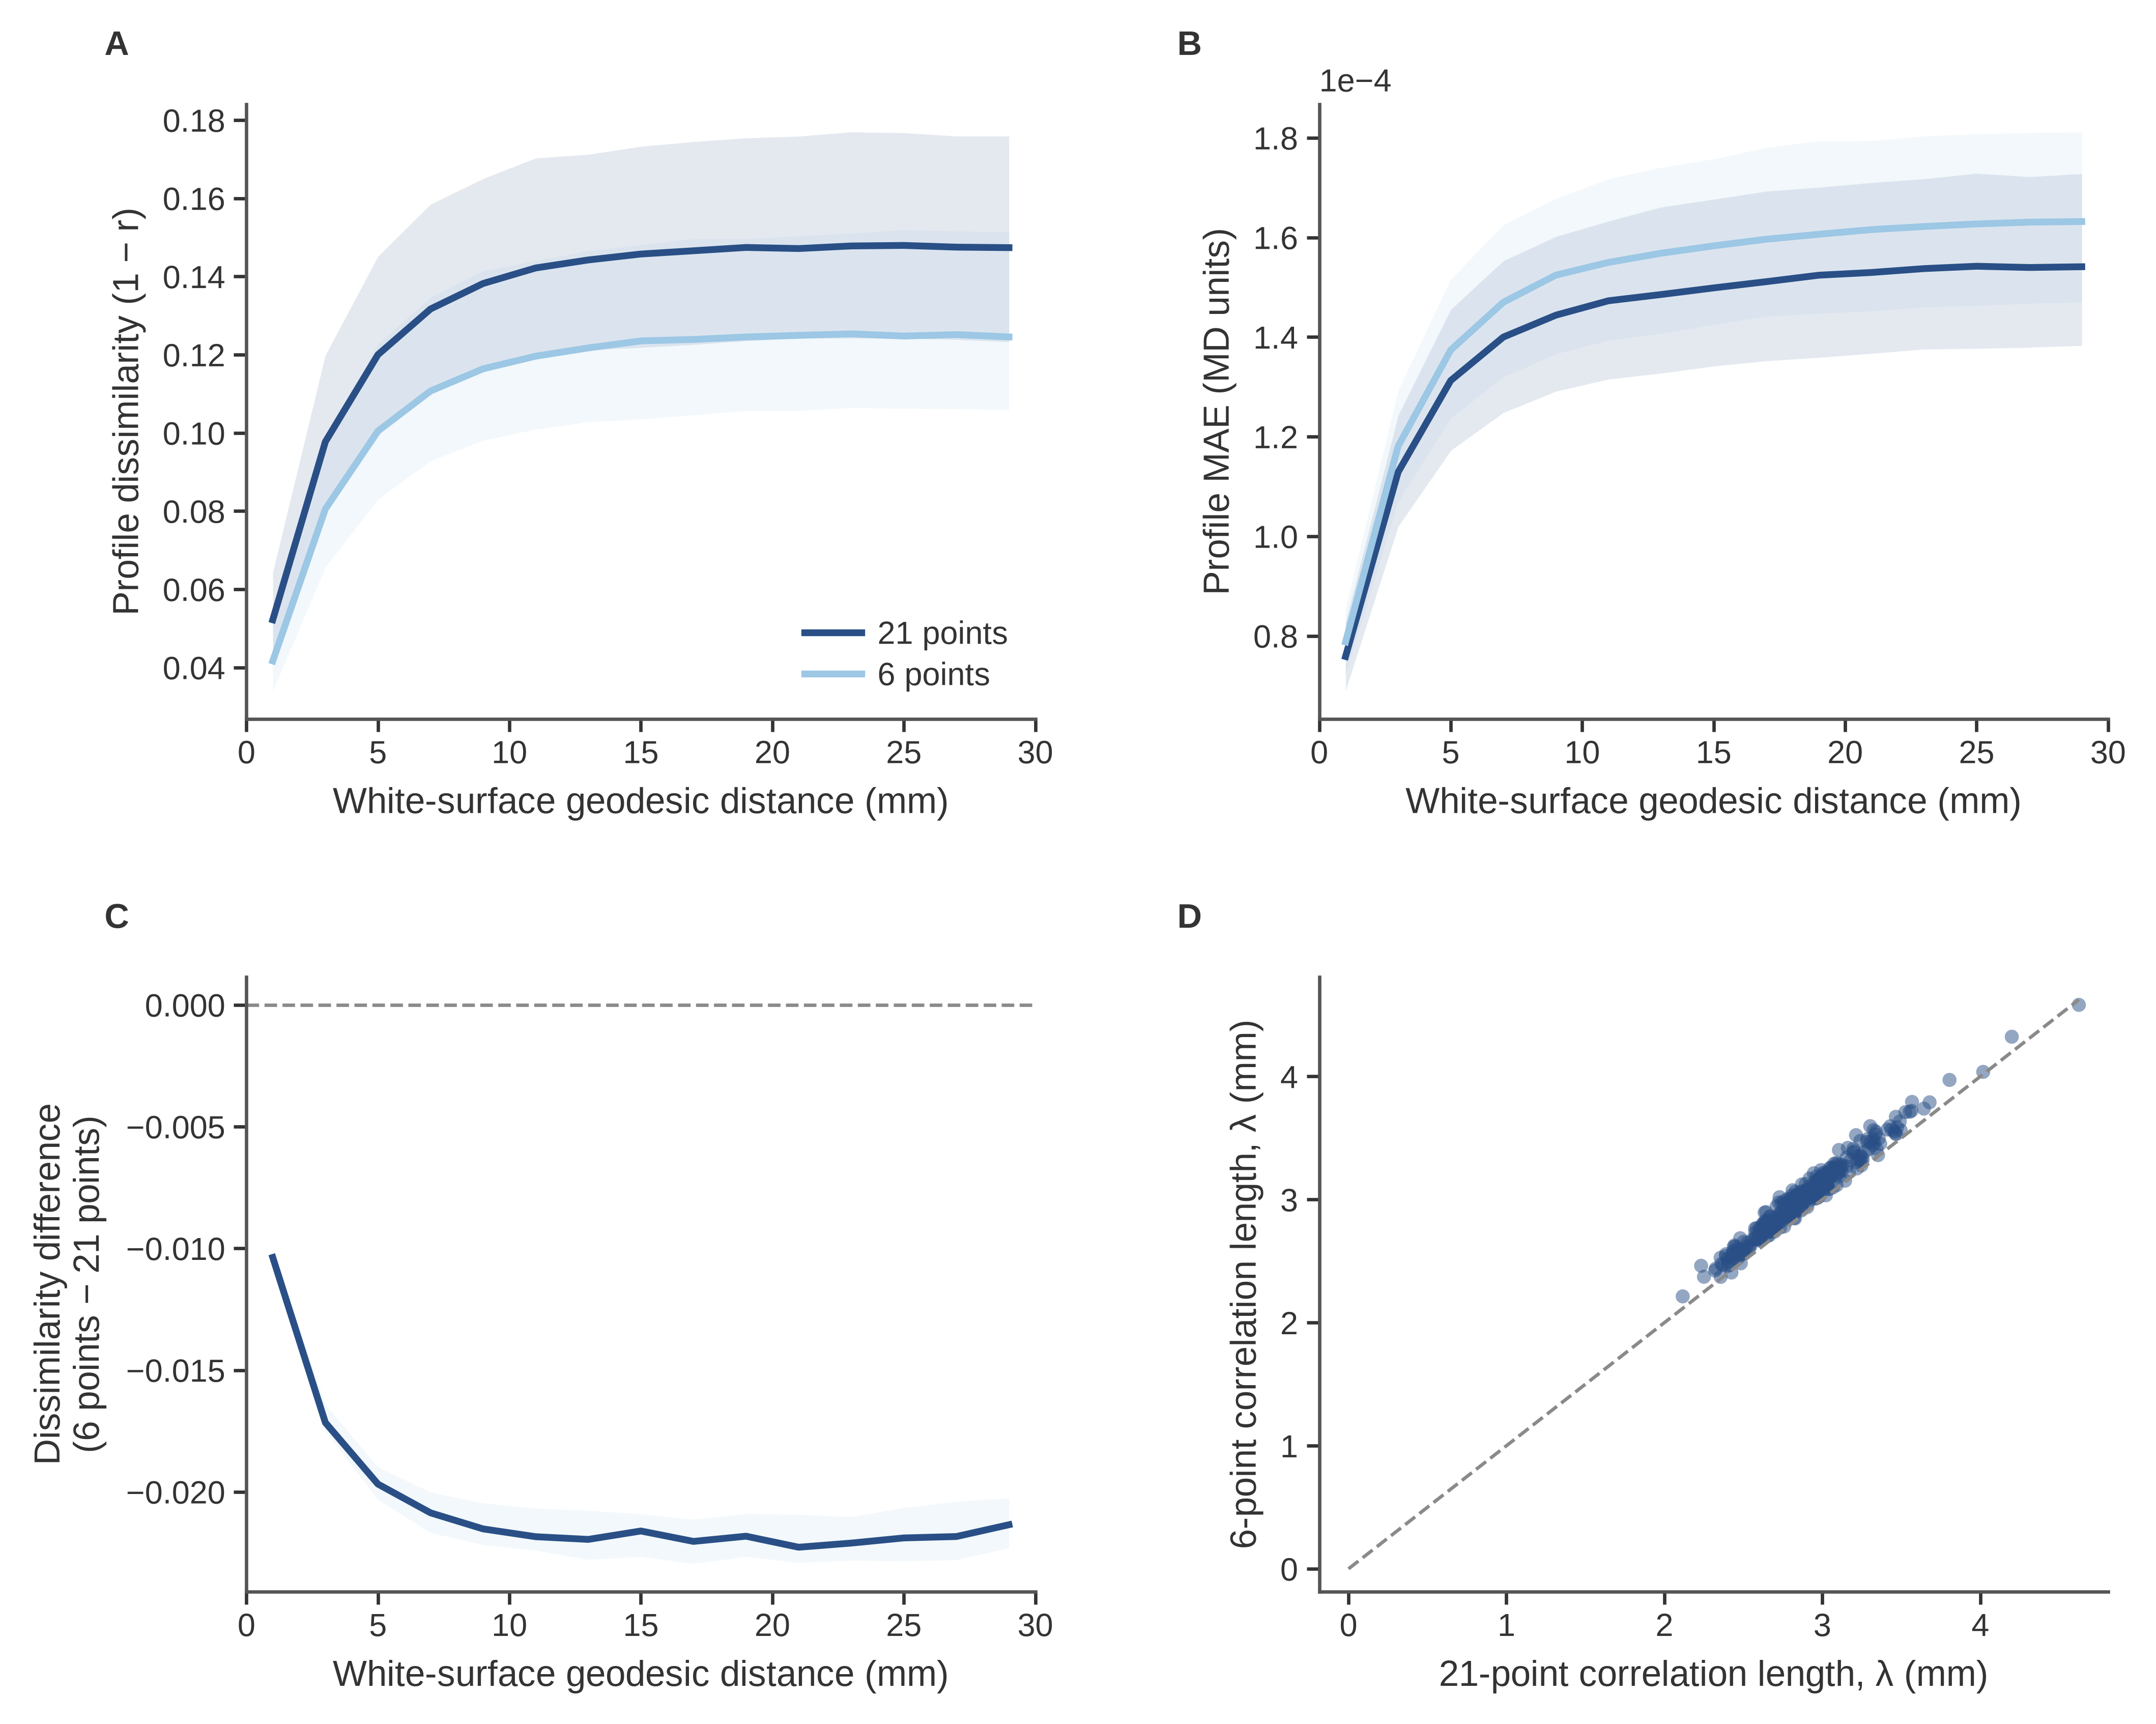

In [6]:
display(Image(filename=str(ROOT / 'supplementary_figure4_6_vs_21_depth_sensitivity.png')))

## Interpretation and scope

The six-point profiles preserve the principal spatial pattern: profile dissimilarity rises rapidly with geodesic distance and approaches a plateau, and complete 6- and 21-point curves are almost perfectly correlated within participant. However, the six-point representation shifts the absolute `1 − r` scale downward and produces a modestly larger fitted correlation length. The result supports qualitative robustness of the spatial organization, but not numerical invariance of dissimilarity or λ and not the optimality of six samples.

This notebook does **not** reanalyse the Figure 4B acquisition-and-sampling null. The original 100 realizations per participant were saved as 21-point aggregate metrics rather than reusable realization-level profiles. Reconstructing a six-point null would require regenerating all null realizations and is outside this sensitivity analysis.

Changing the number of retained profile coordinates does not change the 1-mm DWI acquisition resolution. Adjacent depth values remain highly correlated because of voxel resolution and trilinear interpolation; these coordinates must not be interpreted as independent histological layers.

## Provenance

The subject-level calculations were run as Slurm array job 345016; all 320 tasks completed with no failures. Summary, bootstrap, and figure generation were completed by job 345336. Exact input paths, hashes, parameters, participant IDs, run time, and QC checks are recorded in `run_metadata.json` in the result directory.